In [1]:
import pandas as pd
from datetime import datetime
import os
import plotly.express as px
import plotly.graph_objects as go

In [2]:
# Load the CSV file into a pandas DataFrame
cPath = os.path.dirname(os.path.realpath('./New/'))
file_path = cPath + '/Combined_Terminal_Label.csv'
print(file_path)
myData = pd.read_csv(file_path, parse_dates=['DateTime'], date_format='%Y-%m-%d %H:%M:%S')
myData.set_index('DateTime', drop = False, inplace=True)
# print(myData.head)
print(myData.index.name)

/home/homayoun-valafar/Dropbox/Projects/VisualCode/Python/CAE/New/Combined_Terminal_Label.csv
DateTime


In [3]:
# Find electricity usage data
# We already havet this information. I am using it to check my calculations. They should be the same as in the spreadsheet.

def monthlyUsage(data, mstart, mend):
    usage = []
    etimestamp = pd.date_range(start=mstart, end=mend, freq='M')
    stimestamp = pd.date_range(start=mstart, end=mend, freq='MS')
    sum = 0;
    for i in range(0,len(etimestamp)):
        #print(stimestamp[i], etimestamp[i])
        month = data.loc[stimestamp[i]:etimestamp[i]]
        sum += month['KWH11'].sum()
        usage.append(month['KWH11'].sum())
    print('In the function: ',sum)
    return usage
        
    
Y23_Usage = monthlyUsage(myData, '2023-01-01', '2023-12-31')
print(Y23_Usage)
#print(myData['KWH11'].sum())

In the function:  6941875.5
[517960.0, 484390.0, 555167.5, 550721.5, 602512.0, 526043.0, 698791.0, 737418.5, 640936.5, 556719.5, 522634.5, 548581.5]


In [4]:
def rprt(data, start, end):
    # Calculate the total usage for each year in units of Wh in increments of 15 minutes
    data = data.loc[start:end]
    soffpeak = data[data['label'] == 'sOffPeak']['KWH11'].sum()
    woffpeak = data[data['label'] == 'wOffPeak']['KWH11'].sum()
    wkndoffpeak = data[data['label'] == 'wkndOffPeak']['KWH11'].sum()
    wonpeak = data[data['label'] == 'wOnPeak']['KWH11'].sum()
    sonpeak = data[data['label'] == 'sOnPeak']['KWH11'].sum()
    wonpeakhigh = data[data['label'] == 'wOnPeakHigh']['KWH11'].sum()
    sonpeakhigh = data[data['label'] == 'sOnPeakHigh']['KWH11'].sum()

    # Calculate the average usage for each year in units of Wh in increments of 15 minutes during the On Peak hours 
    # This is a rough calculation and needs to be further refined based month, time, and holidays
    print(data['KWH11'].sum())
    print('wOffPeak:', woffpeak/4)
    print('sOffPeak:', soffpeak/4)
    print('wkndOffPeak:', wkndoffpeak/4)
    print('wOnPeak:', wonpeak/4)
    print('sOnPeak:', sonpeak/4)
    print('wOnPeakHigh:', wonpeakhigh/4)
    print('sOnPeakHigh:', sonpeakhigh/4)
    print('Total:', ((soffpeak+woffpeak+wkndoffpeak)*0.04458 + wonpeak*0.08911 + sonpeak*0.08911 + wonpeakhigh * 0.08911 + sonpeakhigh*0.08911)/4)
    print('Modified Total:', ((soffpeak+woffpeak+wkndoffpeak)*0.057400 + wonpeak*0.068340 + wonpeakhigh * 0.068340)/4 + 1750 + 13451.56 + 962.22)
    print()

myData = myData.sort_index()
rprt(myData, '2023-01-01', '2023-12-31')


7183592.5
wOffPeak: 457720.25
sOffPeak: 329556.25
wkndOffPeak: 506228.375
wOnPeak: 296019.5
sOnPeak: 75551.0
wOnPeakHigh: 48495.125
sOnPeakHigh: 82327.625
Total: 102432.709835
Modified Total: 113955.0892975



In [5]:
data = myData.loc['2023-01-01':'2023-12-31']
#data = myData.loc['2023-08-01':'2023-08-30']
#label_mask = (data['label'] == 'sOnPeakHigh') | (data['label'] == 'sOnPeak') | (data['label'] == 'OffPeak')
label_mask = (data['label'] == 'sOnPeakHigh') | (data['label'] == 'sOnPeak')
month_mask = data.index.month.isin([5, 6, 7, 8, 9])
print(data.loc[month_mask & label_mask]['KW'].max())
print(data.loc[month_mask & label_mask]['KW'].idxmax())
#print(data.loc[month_mask & label_mask]['KW'])
print(data[data['KW'] == 1308])

1698
2023-08-14 21:45:00
                               DateTime  KWH11    KW  Year     Delta  \
DateTime                                                               
2023-04-12 13:30:00 2023-04-12 13:30:00  327.0  1308  2023  0.009444   
2023-04-27 14:00:00 2023-04-27 14:00:00  327.0  1308  2023 -0.000556   
2023-05-14 22:00:00 2023-05-14 22:00:00  327.0  1308  2023 -0.037778   
2023-05-20 00:45:00 2023-05-20 00:45:00  327.0  1308  2023 -0.001111   
2023-06-15 16:45:00 2023-06-15 16:45:00  327.0  1308  2023 -0.004444   
2023-07-28 04:45:00 2023-07-28 04:45:00  327.0  1308  2023  0.018889   
2023-07-28 05:45:00 2023-07-28 05:45:00  327.0  1308  2023 -0.052778   
2023-08-18 03:15:00 2023-08-18 03:15:00  327.0  1308  2023  0.003333   
2023-08-19 02:45:00 2023-08-19 02:45:00  327.0  1308  2023 -0.002222   
2023-09-05 03:15:00 2023-09-05 03:15:00  327.0  1308  2023  0.008889   
2023-09-15 21:30:00 2023-09-15 21:30:00  327.0  1308  2023  0.013889   
2023-09-17 21:30:00 2023-09-17 21:30:00

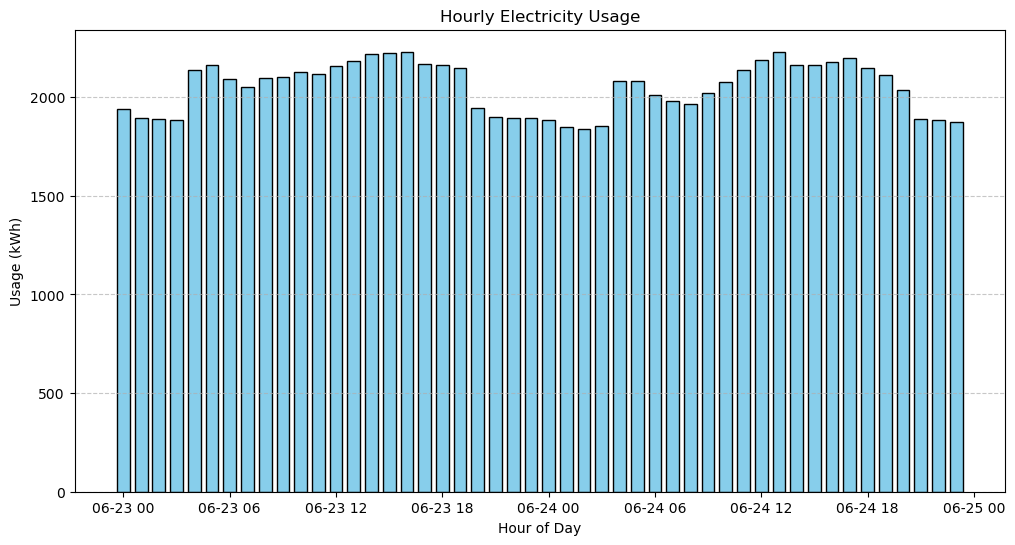

In [7]:
data = myData.loc['2023-06-23':'2023-06-24']
hourly = data['KW'].resample('H').sum()
#print(hourly)

import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.bar(hourly.index, hourly, width=0.03, color='skyblue', edgecolor='black')

plt.title("Hourly Electricity Usage")
plt.xlabel("Hour of Day")
plt.ylabel("Usage (kWh)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

In [12]:
# Get the data corresponding to the same invoice period (April invoice)
data = myData.loc['2024-02-28':'2024-03-27']
# Isolate the on-peak periods (Winter)
label_mask = (data['label'] == 'wOnPeakHigh') | (data['label'] == 'wOnPeak')
print(data.loc[label_mask]['KWH11'].max())
print(data.loc[label_mask]['KWH11'].idxmax())
print(data.loc[label_mask]['KWH11'].sum())
label_mask = (data['label'] == 'wOffPeak')
print(data.loc[label_mask]['KWH11'].max())
print(data.loc[label_mask]['KWH11'].idxmax())
print(data.loc[label_mask]['KWH11'].sum())

267.0
2024-03-14 21:30:00
165664.0
296.0
2024-03-07 12:45:00
224160.5
